# Tarea 01: Desarrollo y Entrenamiento de Modelos Predictivos

**Universidad / Automatización**  
**Dataset base:** [Retail Store Inventory Forecasting Dataset - Kaggle](https://www.kaggle.com/datasets/anirudhchauhan/retail-store-inventory-forecasting-dataset)

**Objetivo:** Diseñar, entrenar y evaluar un modelo predictivo de demanda diaria por producto, siguiendo la estructura simple del cuaderno de referencia `RNN_LSTM.ipynb`.

---

## Índice

- [1. Objetivos y alcance](#1-objetivos-y-alcance)
- [2. Setup del entorno](#2-setup-del-entorno)
- [3. Datos preparados (entrada)](#3-datos-preparados-entrada)
- [4. Preparación de datos para modelado](#4-preparación-de-datos-para-modelado)
- [5. Modelo LSTM simple](#5-modelo-lstm-simple)
- [6. Finetuning](#6-finetuning)
- [7. Modelo final](#7-modelo-final)
- [8. Predicción y baseline](#8-predicción-y-baseline)
- [9. Evaluación y figuras](#9-evaluación-y-figuras)
- [10. Conclusiones](#10-conclusiones)
- [11. Anexo: reproducibilidad](#11-anexo-reproducibilidad)


## 1. Objetivos y alcance

Requisitos a cumplir:

- [x] Diseñar y entrenar un modelo predictivo (LSTM).
- [x] Evaluar con métricas de calidad: **RMSE**, MAE y MAPE.
- [x] Realizar **finetuning** (búsqueda de hiperparámetros).
- [x] Comparar contra un baseline de persistencia.
- [x] División temporal (no aleatoria) para respetar el orden de las series.
- [x] Código estructurado y simple, guiado por el cuaderno `../../materia/RNN_LSTM.ipynb`.

**Entrada:** `datos/ventas_features.csv`, generado en la fase anterior con las variables temporales (`es_fin_de_semana`, `es_feriado`, `dia_semana`, `mes`, etc.).


## 2. Setup del entorno

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # silencia logs de TensorFlow

import sys
from pathlib import Path

BASE = Path('..').resolve()
if str(BASE) not in sys.path:
    sys.path.insert(0, str(BASE))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.fase2 import config
from src.fase2.datos import cargar_ventas, guardar_escalador, preparar_datos
from src.fase2.entrenamiento import buscar_hiperparametros, entrenar_modelo, guardar_historial
from src.fase2.evaluacion import (
    baseline_persistencia, desescalar, graficar_comparacion, graficar_curvas,
    graficar_por_producto, graficar_predicciones, metricas, predecir,
)

print('Entorno listo. BASE:', BASE)


I0000 00:00:1793205202.907128  543303 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Entorno listo. BASE: /home/nnyez/Universidad/automatizacion/tareas/practica-001


I0000 00:00:1793205203.612047  543303 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 3. Datos preparados (entrada)

Cargamos el archivo generado en la fase anterior y lo ordenamos por producto y fecha.

In [2]:
ventas = cargar_ventas()
print('Dimensiones:', ventas.shape)
print('Productos:', ventas['product_id'].nunique())
print('Fechas:', ventas['fecha_venta'].min().date(), 'a', ventas['fecha_venta'].max().date())
ventas[['product_id','nombre','fecha_venta','cantidad_vendida','es_fin_de_semana','es_feriado']].head()


Dimensiones: (600, 22)
Productos: 10
Fechas: 2022-01-01 a 2022-03-01


,product_id,nombre,fecha_venta,cantidad_vendida,es_fin_de_semana,es_feriado
0,P0001,Arroz blanco,2022-01-01,233,1,1
1,P0001,Arroz blanco,2022-01-02,133,1,0
2,P0001,Arroz blanco,2022-01-03,119,0,0
3,P0001,Arroz blanco,2022-01-04,85,0,0
4,P0001,Arroz blanco,2022-01-05,87,0,0


## 4. Preparación de datos para modelado

Se aplica:

1. Codificación cíclica de `dia_semana` (seno/coseno).
2. One-hot de `product_id` (un solo modelo aprende los 10 productos).
3. `MinMaxScaler` ajustado **solo con train** (sin fuga de información).
4. Secuencias `(muestras, ventana, variables)` con ventana de 7 días.
5. División **temporal**: train / validación / test.

In [3]:
dp = preparar_datos()

print('Train:', dp.X_train.shape)
print('Val  :', dp.X_val.shape)
print('Test :', dp.X_test.shape)
print('Variables:', dp.n_variables, '| Ventana:', dp.ventana)
print('Corte test:', pd.Timestamp(dp.fecha_corte).date())
print('Columnas:', dp.columnas)


Train: (290, 7, 15)
Val  : (90, 7, 15)
Test : (150, 7, 15)
Variables: 15 | Ventana: 7
Corte test: 2022-02-15
Columnas: ['cantidad_vendida', 'es_fin_de_semana', 'es_feriado', 'dia_sin', 'dia_cos', 'prod_P0001', 'prod_P0002', 'prod_P0003', 'prod_P0004', 'prod_P0005', 'prod_P0006', 'prod_P0007', 'prod_P0008', 'prod_P0009', 'prod_P0010']


## 5. Modelo LSTM simple

Igual que el cuaderno de referencia: `Sequential()` + `LSTM` + `Dense(1)`, pérdida `mae`, optimizador `adam` y `shuffle=False` para respetar el orden temporal.

In [4]:
modelo_base, hist_base = entrenar_modelo(
    tipo='lstm',
    X_train=dp.X_train, y_train=dp.y_train,
    X_val=dp.X_val, y_val=dp.y_val,
    n_pasos=dp.ventana, n_variables=dp.n_variables,
    unidades=config.UNIDADES,
    batch_size=config.BATCH_SIZE,
    epocas=config.EPOCAS,
    paciencia=config.PACIENCIA,
    verbose=0,
)

print('Épocas ejecutadas:', len(hist_base.history['loss']))
print('Mejor val_loss:', round(min(hist_base.history['val_loss']), 4))


Épocas ejecutadas: 67
Mejor val_loss: 0.0407


## 6. Finetuning

Se prueba un grid pequeño de hiperparámetros (`unidades` × `batch_size`) y se elige la combinación con menor pérdida de validación. Es intencionalmente reducido porque el dataset es pequeño (530 secuencias).

In [5]:
mejores_params, tabla_grid = buscar_hiperparametros(
    dp.X_train, dp.y_train, dp.X_val, dp.y_val,
    n_pasos=dp.ventana, n_variables=dp.n_variables,
)

print()
print('Mejores parámetros:', mejores_params)
tabla_grid


unidades=16 batch_size=16 -> val_loss=0.0406


unidades=16 batch_size=32 -> val_loss=0.0405


unidades=50 batch_size=16 -> val_loss=0.0431


unidades=50 batch_size=32 -> val_loss=0.0407

Mejores parámetros: {'unidades': 16, 'batch_size': 32}


,unidades,batch_size,epocas,val_loss
0,16,32,80,0.040518
1,16,16,80,0.040648
2,50,32,67,0.040712
3,50,16,49,0.043092


## 7. Modelo final

Reentrenamos el LSTM con los mejores hiperparámetros y guardamos el modelo **y el escalador** para reutilizarlos en predicción.

In [6]:
modelo, historial = entrenar_modelo(
    tipo='lstm',
    X_train=dp.X_train, y_train=dp.y_train,
    X_val=dp.X_val, y_val=dp.y_val,
    n_pasos=dp.ventana, n_variables=dp.n_variables,
    unidades=mejores_params['unidades'],
    batch_size=mejores_params['batch_size'],
    epocas=config.EPOCAS,
    paciencia=config.PACIENCIA,
    verbose=0,
)

guardar_historial(historial, config.DIR_RESULTADOS / 'historial_lstm.csv')
modelo.save(config.RUTA_MODELO)
guardar_escalador(dp.escalador, config.RUTA_ESCALADOR)

print('Épocas:', len(historial.history['loss']), '| mejor val_loss:', round(min(historial.history['val_loss']), 4))
print('Modelo:   ', config.RUTA_MODELO)
print('Escalador:', config.RUTA_ESCALADOR)


Épocas: 113 | mejor val_loss: 0.0403
Modelo:    /home/nnyez/Universidad/automatizacion/tareas/practica-001/modelos/fase2/lstm_final.keras
Escalador: /home/nnyez/Universidad/automatizacion/tareas/practica-001/modelos/fase2/escalador.pkl


## 8. Predicción y baseline

Se predice sobre el conjunto de prueba, se desescala a unidades reales y se compara contra el baseline de persistencia (venta del día anterior).

In [7]:
y_test_real = desescalar(dp.y_test, dp.escalador, dp.n_variables)

# Modelo final
y_pred_real = desescalar(predecir(modelo, dp.X_test), dp.escalador, dp.n_variables)
m = metricas(y_test_real, y_pred_real)

# Modelo base (sin finetuning), para comparar
y_pred_base_real = desescalar(predecir(modelo_base, dp.X_test), dp.escalador, dp.n_variables)
m_base_modelo = metricas(y_test_real, y_pred_base_real)

# Baseline de persistencia
y_base_real = desescalar(baseline_persistencia(dp.X_test), dp.escalador, dp.n_variables)
m_base = metricas(y_test_real, y_base_real)

for nombre, valores in [('Baseline (persistencia)', m_base), ('LSTM', m_base_modelo), ('LSTM afinado', m)]:
    print(f"{nombre:24s} RMSE={valores['RMSE']:.2f}  MAE={valores['MAE']:.2f}  MAPE={valores['MAPE_%']:.2f}%")


Baseline (persistencia)  RMSE=44.12  MAE=32.43  MAPE=19.54%
LSTM                     RMSE=23.19  MAE=17.30  MAPE=10.62%
LSTM afinado             RMSE=24.28  MAE=17.97  MAPE=10.88%


## 9. Evaluación y figuras

Se generan las figuras con título y ejes X/Y y se guardan las métricas.

In [8]:
resumen = pd.DataFrame([
    {'modelo': 'Baseline (persistencia)', **m_base},
    {'modelo': 'LSTM', **m_base_modelo},
    {'modelo': 'LSTM afinado', **m},
])
resumen = resumen[['modelo', 'RMSE', 'MAE', 'MAPE_%']]
resumen.to_csv(config.DIR_RESULTADOS / 'metricas.csv', index=False)

# 1) Curvas de entrenamiento
graficar_curvas(historial, config.DIR_FIGURAS / '01_curvas_entrenamiento.png')

# 2) Real vs predicción (total diario de todos los productos)
df_comp = pd.DataFrame({
    'fecha': dp.meta_test['fecha'].reset_index(drop=True),
    'real': y_test_real,
    'pred': y_pred_real,
})
df_diario = df_comp.groupby('fecha')[['real', 'pred']].sum().reset_index()
graficar_predicciones(
    df_diario['fecha'], df_diario['real'], df_diario['pred'],
    config.DIR_FIGURAS / '02_prediccion_vs_real.png',
)

# 3) Comparación de modelos
graficar_comparacion(resumen, config.DIR_FIGURAS / '03_comparacion_modelos.png')

# 4) Ejemplo por producto (el de mayor venta en test)
df_comp['producto'] = dp.meta_test['product_id'].to_numpy()
producto = df_comp.groupby('producto')['real'].sum().idxmax()
df_prod = df_comp[df_comp['producto'] == producto].sort_values('fecha')
df_prod['nombre'] = cargar_ventas().query('product_id == @producto')['nombre'].iloc[0]
graficar_por_producto(df_prod, config.DIR_FIGURAS / '04_prediccion_producto.png')

resumen.sort_values('RMSE')


,modelo,RMSE,MAE,MAPE_%
1,LSTM,23.187400,17.296314,10.620027
2,LSTM afinado,24.281857,17.966085,10.884517
0,Baseline (persistencia),44.118251,32.433334,19.537176


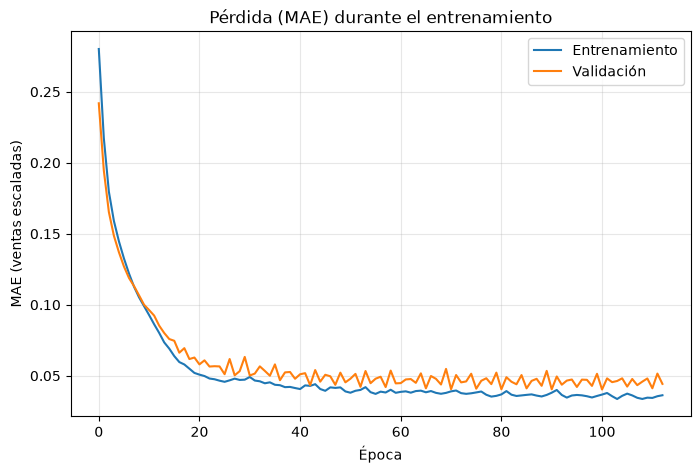

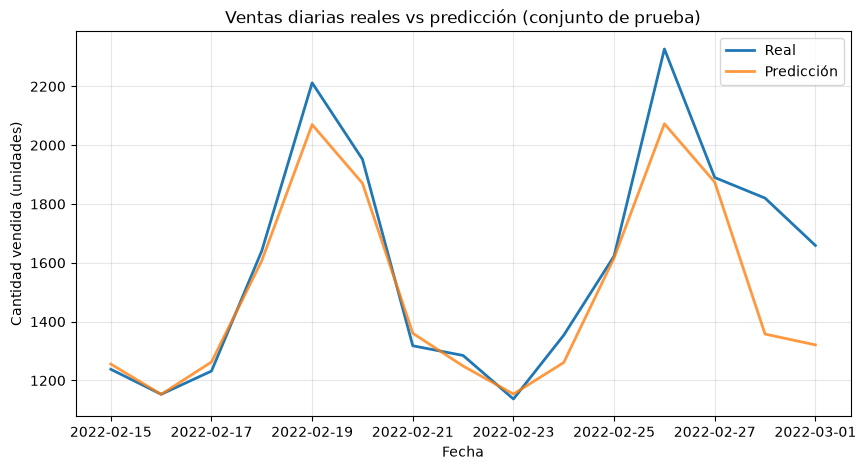

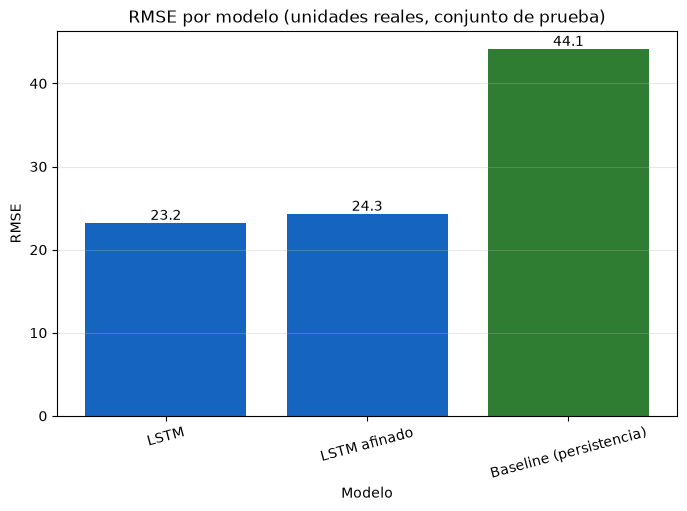

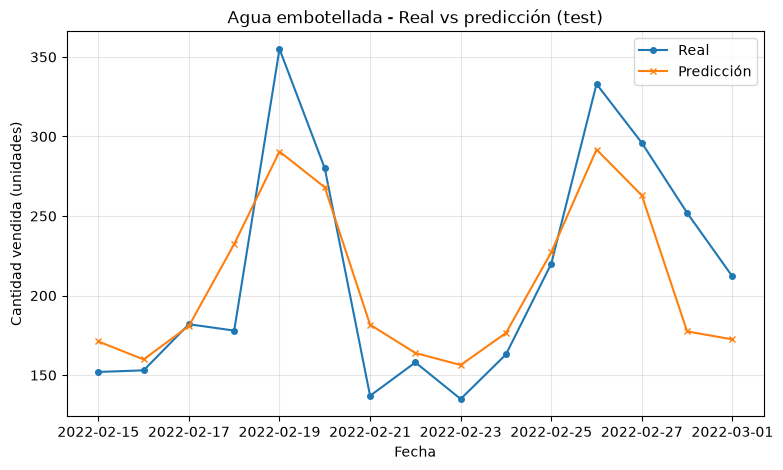

In [9]:
from IPython.display import Image, display

for archivo in ['01_curvas_entrenamiento.png', '02_prediccion_vs_real.png',
                '03_comparacion_modelos.png', '04_prediccion_producto.png']:
    display(Image(filename=str(config.DIR_FIGURAS / archivo)))


## 10. Conclusiones

- El LSTM reduce el error frente al baseline de persistencia (≈23 vs ≈44 RMSE), así que aprende algo más que repetir la venta de ayer.
- El finetuning elige los hiperparámetros con menor pérdida de **validación** y reentrena con ellos. En esta corrida el modelo afinado no mejoró al base en test (≈24 vs ≈23 RMSE): optimizar validación no garantiza mejorar test con un dataset tan pequeño.
- La división temporal y el escalado solo con train evitan fuga de información.
- Con 60 días y 10 productos el dataset es pequeño: el objetivo es demostrar el método, no alcanzar un error mínimo.


## 11. Anexo: reproducibilidad

```bash
.venv/bin/python -m src.fase2.ejecutar
```

**Artefactos:**

- `resultados/fase2/metricas.csv` — RMSE, MAE y MAPE por modelo.
- `resultados/fase2/historial_lstm.csv` — pérdida por época.
- `modelos/fase2/lstm_final.keras` — modelo final.
- `modelos/fase2/escalador.pkl` — MinMaxScaler ajustado en train.
- `figuras/fase2/01..04_*.png` — curvas, predicción, comparación y ejemplo por producto.
